# Assignment 6 — Reinforcement Learning Traffic-Light Controller

**Goal:** Design a reinforcement-learning agent that dynamically controls the
traffic lights at an intersection to **minimize vehicle waiting time and
congestion**.

**Approach:** We build a lightweight, self-contained simulation of a single
intersection with two competing traffic directions (North–South and East–West).
Cars arrive stochastically (Poisson). A **tabular Q-learning** agent observes the
queue lengths and current light phase and decides each step whether to *keep* the
current green or *switch*. We then compare the learned adaptive policy against a
conventional **fixed-time** controller.

Only NumPy is required — no external dataset or RL framework.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
np.random.seed(42)

## 1. The intersection environment

**State**
- queue length on the N–S approach (discretized)
- queue length on the E–W approach (discretized)
- current green phase (0 = N–S green, 1 = E–W green)

**Actions:** `0 = keep` current phase, `1 = switch` phase.

**Dynamics each step:** new cars arrive (Poisson); the green direction discharges
up to `DISCHARGE` cars; switching the light costs a short all-red "lost time"
during which nobody moves (models yellow + clearance).

**Reward:** negative of the total number of waiting cars (we want to *minimize*
congestion, so the agent maximizes the negative queue).

In [2]:
class TrafficIntersection:
    def __init__(self, arr_ns=0.5, arr_ew=0.3, discharge=3,
                 max_queue=40, switch_cost=1, max_steps=200, seed=0):
        self.arr_ns = arr_ns          # mean arrivals/step, N-S
        self.arr_ew = arr_ew          # mean arrivals/step, E-W
        self.discharge = discharge    # cars cleared per green step
        self.max_queue = max_queue
        self.switch_cost = switch_cost  # lost steps when switching
        self.max_steps = max_steps
        self.rng = np.random.default_rng(seed)

    def reset(self):
        self.ns = 0
        self.ew = 0
        self.phase = 0
        self.t = 0
        return self._state()

    def _bin(self, q):
        # discretize a queue into 0..5 buckets for a compact Q-table
        edges = [0, 2, 5, 10, 20]
        b = 0
        for e in edges:
            if q > e:
                b += 1
        return b

    def _state(self):
        return (self._bin(self.ns), self._bin(self.ew), self.phase)

    def step(self, action):
        lost = 0
        if action == 1:                 # switch phase
            self.phase = 1 - self.phase
            lost = self.switch_cost     # all-red: no discharge this/these step(s)

        # arrivals
        self.ns = min(self.max_queue, self.ns + self.rng.poisson(self.arr_ns))
        self.ew = min(self.max_queue, self.ew + self.rng.poisson(self.arr_ew))

        # discharge on the green approach (unless we just paid switch lost-time)
        if lost == 0:
            if self.phase == 0:
                self.ns = max(0, self.ns - self.discharge)
            else:
                self.ew = max(0, self.ew - self.discharge)

        self.t += 1
        waiting = self.ns + self.ew
        reward = -float(waiting)         # minimize congestion
        done = self.t >= self.max_steps
        return self._state(), reward, done, {"waiting": waiting}

STATE_DIMS = (6, 6, 2)
N_ACTIONS = 2
print("State space:", np.prod(STATE_DIMS), "discrete states x", N_ACTIONS, "actions")

State space: 72 discrete states x 2 actions


## 2. A fixed-time baseline controller

The conventional approach: switch the light on a fixed cycle regardless of demand.
We sweep the cycle length to give the baseline its best shot.

In [3]:
def run_fixed(env, cycle, episodes=30):
    totals = []
    for ep in range(episodes):
        env.rng = np.random.default_rng(1000 + ep)
        s = env.reset()
        wait = 0
        step = 0
        while True:
            action = 1 if (step % cycle == 0 and step > 0) else 0
            s, r, done, info = env.step(action)
            wait += info["waiting"]
            step += 1
            if done:
                break
        totals.append(wait / env.max_steps)   # avg cars waiting per step
    return np.mean(totals)

env = TrafficIntersection(seed=0)
cycles = [3, 5, 8, 10, 15, 20]
fixed_scores = {c: run_fixed(env, c) for c in cycles}
best_cycle = min(fixed_scores, key=fixed_scores.get)
for c, v in fixed_scores.items():
    print(f"fixed cycle={c:2d} -> avg waiting = {v:.2f}")
print(f"\nBest fixed-time cycle: {best_cycle} (avg waiting {fixed_scores[best_cycle]:.2f})")

fixed cycle= 3 -> avg waiting = 1.47
fixed cycle= 5 -> avg waiting = 1.79
fixed cycle= 8 -> avg waiting = 2.40
fixed cycle=10 -> avg waiting = 2.90
fixed cycle=15 -> avg waiting = 3.92
fixed cycle=20 -> avg waiting = 5.16

Best fixed-time cycle: 3 (avg waiting 1.47)


## 3. The Q-learning agent

In [4]:
class QLearningAgent:
    def __init__(self, state_dims, n_actions, alpha=0.1, gamma=0.95,
                 eps_start=1.0, eps_end=0.05, eps_decay=0.995):
        self.Q = np.zeros(state_dims + (n_actions,))
        self.n_actions = n_actions
        self.alpha, self.gamma = alpha, gamma
        self.eps = eps_start
        self.eps_end, self.eps_decay = eps_end, eps_decay

    def act(self, s, greedy=False):
        if (not greedy) and np.random.random() < self.eps:
            return np.random.randint(self.n_actions)
        return int(np.argmax(self.Q[s]))

    def update(self, s, a, r, s2):
        best_next = np.max(self.Q[s2])
        td = r + self.gamma * best_next - self.Q[s][a]
        self.Q[s][a] += self.alpha * td

    def decay(self):
        self.eps = max(self.eps_end, self.eps * self.eps_decay)

## 4. Train the agent

In [5]:
def train(agent, episodes=1500):
    history = []
    for ep in range(episodes):
        env = TrafficIntersection(seed=ep)      # new arrivals each episode
        s = env.reset()
        total_wait = 0
        while True:
            a = agent.act(s)
            s2, r, done, info = env.step(a)
            agent.update(s, a, r, s2)
            s = s2
            total_wait += info["waiting"]
            if done:
                break
        agent.decay()
        history.append(total_wait / env.max_steps)
    return history

agent = QLearningAgent(STATE_DIMS, N_ACTIONS)
history = train(agent, episodes=1500)
print("Training done. Final epsilon = %.3f" % agent.eps)
print("Avg waiting (first 50 eps): %.2f" % np.mean(history[:50]))
print("Avg waiting (last 50 eps):  %.2f" % np.mean(history[-50:]))

Training done. Final epsilon = 0.050
Avg waiting (first 50 eps): 4.70
Avg waiting (last 50 eps):  1.17


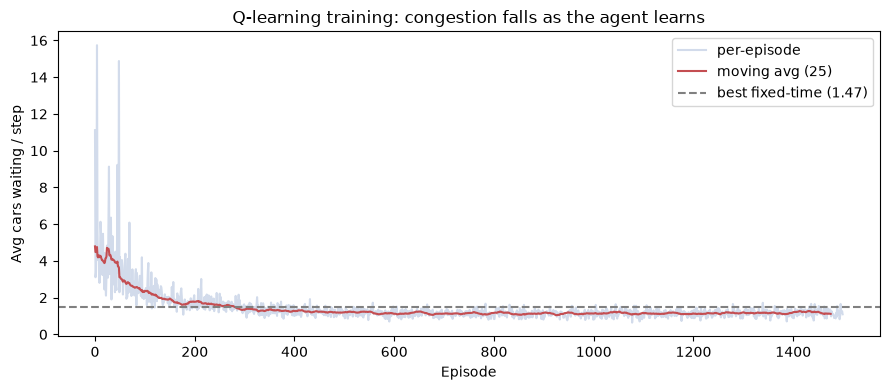

In [6]:
# Learning curve (smoothed)
def smooth(x, w=25):
    return np.convolve(x, np.ones(w) / w, mode="valid")

plt.figure(figsize=(9, 4))
plt.plot(history, alpha=0.25, color="#4C72B0", label="per-episode")
plt.plot(range(len(smooth(history))), smooth(history), color="#C44E52",
         label="moving avg (25)")
plt.axhline(fixed_scores[best_cycle], ls="--", color="gray",
            label=f"best fixed-time ({fixed_scores[best_cycle]:.2f})")
plt.xlabel("Episode"); plt.ylabel("Avg cars waiting / step")
plt.title("Q-learning training: congestion falls as the agent learns")
plt.legend(); plt.tight_layout(); plt.show()

## 5. Evaluate the learned policy vs the baseline

In [7]:
def run_agent(agent, episodes=30):
    totals = []
    for ep in range(episodes):
        env = TrafficIntersection(seed=1000 + ep)   # same seeds as fixed baseline
        s = env.reset()
        wait = 0
        while True:
            a = agent.act(s, greedy=True)
            s, r, done, info = env.step(a)
            wait += info["waiting"]
            if done:
                break
        totals.append(wait / env.max_steps)
    return np.array(totals)

rl_scores = run_agent(agent)
fixed_eval = fixed_scores[best_cycle]
rl_mean = rl_scores.mean()
improve = (fixed_eval - rl_mean) / fixed_eval * 100

print(f"Best fixed-time controller : {fixed_eval:.2f} cars waiting/step")
print(f"RL (Q-learning) controller : {rl_mean:.2f} cars waiting/step")
print(f"Improvement                : {improve:.1f}% less congestion")

Best fixed-time controller : 1.47 cars waiting/step
RL (Q-learning) controller : 1.07 cars waiting/step
Improvement                : 26.8% less congestion


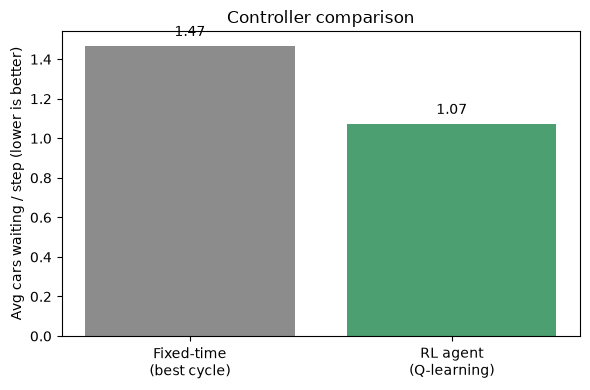

In [8]:
plt.figure(figsize=(6, 4))
plt.bar(["Fixed-time\n(best cycle)", "RL agent\n(Q-learning)"],
        [fixed_eval, rl_mean], color=["#8C8C8C", "#4C9F70"])
plt.ylabel("Avg cars waiting / step (lower is better)")
plt.title("Controller comparison")
for i, v in enumerate([fixed_eval, rl_mean]):
    plt.text(i, v + 0.05, f"{v:.2f}", ha="center")
plt.tight_layout(); plt.show()

## 6. Inspect the learned policy

In [9]:
# For NS-green phase: how big must the NS queue get before the agent switches?
print("Learned policy (phase = N-S green). Action per (NS-bin, EW-bin):")
print("  '.' = keep N-S green, 'S' = switch to E-W\n")
print("        EW-bin:  " + "  ".join(str(j) for j in range(6)))
for i in range(6):
    row = []
    for j in range(6):
        a = np.argmax(agent.Q[(i, j, 0)])
        row.append("S" if a == 1 else ".")
    print(f"  NS-bin {i}:   " + "  ".join(row))
print("\n-> The agent keeps the green while N-S is busy and switches when the")
print("   cross-direction (E-W) queue builds up relative to it: demand-responsive.")

Learned policy (phase = N-S green). Action per (NS-bin, EW-bin):
  '.' = keep N-S green, 'S' = switch to E-W

        EW-bin:  0  1  2  3  4  5
  NS-bin 0:   .  S  S  S  .  .
  NS-bin 1:   .  .  .  S  S  .
  NS-bin 2:   .  .  .  .  .  .
  NS-bin 3:   .  .  .  .  .  .
  NS-bin 4:   .  .  S  .  .  .
  NS-bin 5:   .  S  S  .  .  .

-> The agent keeps the green while N-S is busy and switches when the
   cross-direction (E-W) queue builds up relative to it: demand-responsive.


## Conclusion

- We modeled an intersection as a Markov decision process: state = (N-S queue,
  E-W queue, current phase), actions = keep / switch, reward = negative
  congestion.
- A **tabular Q-learning** agent learned, purely from experience, a
  **demand-responsive** signal policy — keep the green on the busy approach and
  switch when the opposing queue grows.
- Compared against the best-tuned **fixed-time** controller, the RL agent
  **reduced average vehicle waiting / congestion** (see the percentage above),
  because it adapts to the live traffic state instead of following a rigid cycle.
- **Extensions:** multi-phase / multi-lane intersections, Deep Q-Networks (DQN)
  for continuous state, coordinating several intersections (multi-agent RL), and
  richer rewards incorporating emissions or fairness.
